In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip install -q gdown
import gdown

file_id = "1XysWah6Ru87i27lRvMRTzuzV_LXJZRQB"
gdown.download(f"https://drive.google.com/uc?id={file_id}", "model.pth", quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1XysWah6Ru87i27lRvMRTzuzV_LXJZRQB
From (redirected): https://drive.google.com/uc?id=1XysWah6Ru87i27lRvMRTzuzV_LXJZRQB&confirm=t&uuid=6168603b-febb-479a-9299-b6ca6f779b1d
To: /content/model.pth
100%|██████████| 134M/134M [00:02<00:00, 66.7MB/s]


'model.pth'

In [3]:
# imports
import json, random
from pathlib import Path
from tqdm.auto import tqdm

import numpy as np
import pandas as pd

from torch import nn
import torch, torchvision
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GroupShuffleSplit

import matplotlib.pyplot as plt

# seed
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# device settings
if torch.cuda.is_available():
    device_id = torch.cuda.current_device()
    device = torch.device('cuda:%d' % device_id)
    print(torch.cuda.get_device_name(device_id))
else:
    device = torch.device('cpu')

Tesla T4


In [4]:
dataset = load_dataset("geraldmc/plantvillage-full")

data = dataset["train"]

train_dataset = data.filter(lambda x: x["split"] == "train")
test_dataset = data.filter(lambda x: x["split"] == "test")

In [5]:
model = resnet18(weights=ResNet18_Weights.DEFAULT)
NUM_CLASSES = 38
model.fc = nn.Linear(
    model.fc.in_features,
    NUM_CLASSES
)

BEST_CHECKPOINT = '/content/model.pth'
checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
model = model.to(device)


In [6]:
class PlantVillageDataset(Dataset):
    def __init__(self, dataset, apply):
        self.dataset = dataset
        self.apply = apply

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        sample = self.dataset[idx]
        image = sample["image"].convert("RGB")
        label = int(sample["class_idx"])

        IMG_SIZE = 224
        mean = [0.485, 0.456, 0.406]
        std = [0.229, 0.224, 0.225]

        image = transforms.Resize((IMG_SIZE, IMG_SIZE))(image)
        image = transforms.ToTensor()(image)
        image = self.apply(image)
        image = transforms.Normalize(mean=mean, std=std)(image)


        return image, label



def get_dataloader(dataset, apply, batch_size, shuffle=False):
    dataset = PlantVillageDataset(dataset, apply)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)
    return dataloader

apply = lambda x: x
train_loader = get_dataloader(train_dataset, apply, batch_size=32, shuffle=True)
test_loader = get_dataloader(test_dataset, apply, batch_size=32, shuffle=False)

In [7]:
def get_acc(model, dataloader, n=100):
    total = 0
    correct = 0
    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = torch.argmax(model(images), dim=1)
        correct += (outputs == labels).sum().item()
        total += len(labels)
        if total>n:
            break
    return correct / total

def get_acc_scores(model, dataset, apply, strengths):
    accs = []
    for strength in tqdm(strengths):
        func = lambda img: apply(img, strength)
        dataloader = get_dataloader(dataset, func, batch_size=32)
        acc = get_acc(model, dataloader)
        accs.append(acc)
    return accs



In [8]:
def apply_gray(img, s):
    target = transforms.Grayscale(num_output_channels=3)(img)
    return s * target + (1 - s) * img


def apply_darken(img, s):
    target = torch.zeros_like(img)
    return s * target + (1 - s) * img


def apply_brighten(img, s):
    target = torch.ones_like(img)
    return s * target + (1 - s) * img


def apply_contrast(img, s):
    target = torch.full_like(img, img.mean().item())
    return s * target + (1 - s) * img


def apply_noise(img, s):
    target = torch.rand_like(img)
    return s * target + (1 - s) * img


def apply_blur(img, s):
    target = transforms.GaussianBlur(kernel_size=31, sigma=8.0)(img)
    return s * target + (1 - s) * img


# applys = [apply_gray, apply_darken, apply_brighten, apply_contrast, apply_noise, apply_blur]
# final_accs = []
# for func in applys:
#     strengths = np.linspace(0, 1, num=10)
#     accs = get_acc_scores(model, test_dataset, func, strengths=strengths)
#     final_accs.append(accs)

#     plt.plot(strengths, accs)
#     plt.show()

Grayscale


  0%|          | 0/10 [00:00<?, ?it/s]

Darken


  0%|          | 0/10 [00:00<?, ?it/s]

Brighten


  0%|          | 0/10 [00:00<?, ?it/s]

... (2 outputs left out)

Noise


  0%|          | 0/10 [00:00<?, ?it/s]

Blur


  0%|          | 0/10 [00:00<?, ?it/s]

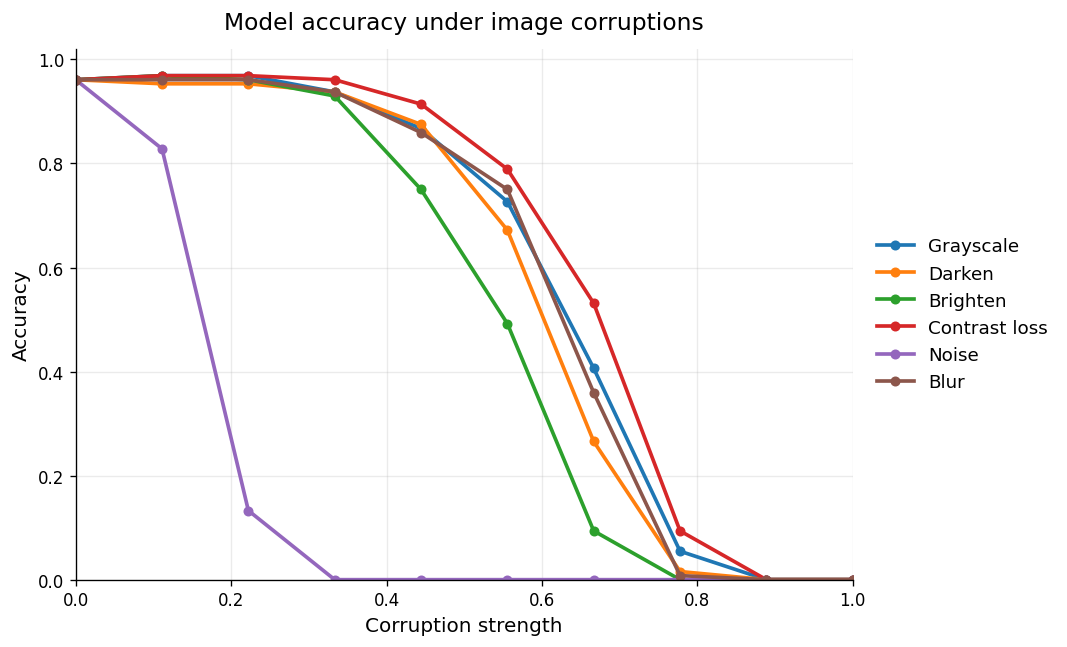

In [9]:
applys = {
    "Grayscale": apply_gray,
    "Darken": apply_darken,
    "Brighten": apply_brighten,
    "Contrast loss": apply_contrast,
    "Noise": apply_noise,
    "Blur": apply_blur,
}

strengths = np.linspace(0, 1, num=10)
final_accs = {}
for name, func in applys.items():
    print(name)
    final_accs[name] = get_acc_scores(model, test_dataset, func, strengths=strengths)

colors = plt.cm.tab10.colors
fig, ax = plt.subplots(figsize=(9, 5.5), dpi=120)

for i, (name, accs) in enumerate(final_accs.items()):
    ax.plot(
        strengths,
        accs,
        marker="o",
        markersize=5,
        linewidth=2.2,
        color=colors[i],
        label=name,
    )

ax.set_xlabel("Corruption strength", fontsize=12)
ax.set_ylabel("Accuracy", fontsize=12)
ax.set_title("Model accuracy under image corruptions", fontsize=14, pad=12)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(True, alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=11)

fig.tight_layout()
plt.show()

In [11]:
import onnxruntime
print(onnxruntime.get_available_providers())

['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']


In [22]:
from rembg import remove, new_session

to_pil = transforms.ToPILImage()
to_tensor = transforms.ToTensor()
session = new_session("u2net", providers=["CUDAExecutionProvider", "CPUExecutionProvider"])


def get_mask(img):
    return to_tensor(remove(to_pil(img), session=session, only_mask=True))


def apply_clean(img, s):
    return img


def apply_remove_background(img, s):
    mask = get_mask(img)
    target = torch.full_like(img, 0.5)
    removed = mask * img + (1 - mask) * target
    return s * removed + (1 - s) * img


def apply_remove_foreground(img, s):
    mask = get_mask(img)
    target = torch.full_like(img, 0.5)
    removed = (1 - mask) * img + mask * target
    return s * removed + (1 - s) * img


variants = {
    "Clean": apply_clean,
    "Background removed": apply_remove_background,
    "Foreground removed": apply_remove_foreground,
}

accs = {}
for name, func in variants.items():
    print(name)
    accs[name] = get_acc_scores(model, test_dataset, func, strengths=[1.0])[0]

Clean


  0%|          | 0/1 [00:00<?, ?it/s]

Background removed


  0%|          | 0/1 [00:00<?, ?it/s]

Foreground removed


  0%|          | 0/1 [00:00<?, ?it/s]

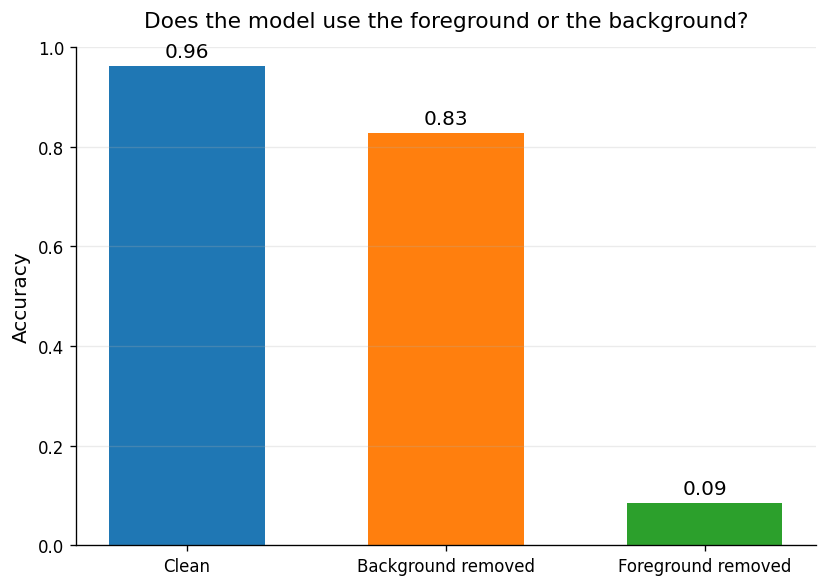

In [21]:
colors = plt.cm.tab10.colors
fig, ax = plt.subplots(figsize=(7, 5), dpi=120)
bars = ax.bar(accs.keys(), accs.values(), color=colors[:3], width=0.6)

ax.bar_label(bars, labels=[f"{v:.2f}" for v in accs.values()], padding=3, fontsize=12)
ax.set_ylabel("Accuracy", fontsize=12)
ax.set_title("Does the model use the foreground or the background?", fontsize=13, pad=12)
ax.set_ylim(0, 1)
ax.grid(True, axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()